# Práctica 4: Clasificación de Dígitos en MNIST mediante Transfer Learning

**Autor:** Manuel Farfán Fernández  

---

## 1. Introducción y Planteamiento del Problema

El objetivo de esta práctica es implementar y evaluar modelos de aprendizaje profundo utilizando **Transfer Learning** (aprendizaje por transferencia) a partir de modelos pre-entrenados de base para clasificar el conjunto de datos **MNIST** (dígitos escritos a mano) utilizado en prácticas anteriores. Se probarán diferentes propuestas arquitectónicas y configuraciones, comparando los resultados de forma gráfica y numérica. A partir de esta comparativa, se determinará qué configuración obtiene el mejor rendimiento para el conjunto de datos y se guardará el modelo entrenado óptimo en disco para su posterior uso.

---
## 2. Descripción de las Arquitecturas Base y Configuraciones de Transfer Learning (MNIST Multiclase)

Para esta práctica de aprendizaje por transferencia, seleccionaremos dos de los modelos pre-entrenados más representativos del estado del arte: **VGG16** (caracterizado por su estructura secuencial en bloques homogéneos) y **ResNet50** (caracterizado por la incorporación de bloques residuales con conexiones de salto).

Dado que el conjunto de datos MNIST consta de imágenes en escala de grises de $28 \times 28$ píxeles, los modelos base recibirán un preprocesamiento de reescalado a $32 \times 32$ píxeles (o superior requerido por la arquitectura) y expansión a 3 canales (RGB). Para mantener una ejecución ágil y evitar tiempos de cómputo excesivos (*evitar esperar un siglo*), el tronco convolucional base se mantendrá congelado (`frozen`), entrenando únicamente las capas de clasificación superiores que añadiremos a medida.

Para cada modelo base, evaluaremos **tres configuraciones optimizadas y ligeras** para la cabeza de clasificación (*classifier head*):

---

### 2.1. Modelo Base 1: VGG16 (Visual Geometry Group)
- **Filosofía del modelo base:** Extracción jerárquica mediante bloques convolucionales uniformes con filtros pequeños ($3 \times 3$).
- **Configuraciones de la cabeza adaptada:**
  - **Configuración 1.1 (Clasificador Ligero):**
    - `GlobalAveragePooling2D`: Reduce el mapa de características promediando espacialmente, evitando la explosión de parámetros del `Flatten`.
    - `Dense (64 neuronas, ReLU)`: Integración básica de características.
    - `Dense (10 neuronas, Softmax)`: Capa de salida categórica.
  - **Configuración 1.2 (Clasificador con Regularización - Dropout):**
    - `GlobalAveragePooling2D` $\rightarrow$ `Dense (128 neuronas, ReLU)` $\rightarrow$ `Dropout (30%)` para prevenir sobreajuste $\rightarrow$ `Dense (10 neuronas, Softmax)`.
  - **Configuración 1.3 (Clasificador Profundo Dual):**
    - `GlobalAveragePooling2D` $\rightarrow$ `Dense (256 neuronas, ReLU)` $\rightarrow$ `Dense (64 neuronas, ReLU)` $\rightarrow$ `Dense (10 neuronas, Softmax)`.

---

### 2.2. Modelo Base 2: ResNet50 (Residual Network)
- **Filosofía del modelo base:** Uso de conexiones residuales (*skip connections*) que facilitan la propagación del gradiente en redes profundas sin degradación.
- **Configuraciones de la cabeza adaptada:**
  - **Configuración 2.1 (Clasificador Ligero):**
    - `GlobalAveragePooling2D` $\rightarrow$ `Dense (32 neuronas, ReLU)` $\rightarrow$ `Dense (10 neuronas, Softmax)`.
  - **Configuración 2.2 (Clasificador con Regularización - Dropout):**
    - `GlobalAveragePooling2D` $\rightarrow$ `Dense (64 neuronas, ReLU)` $\rightarrow$ `Dropout (30%)` $\rightarrow$ `Dense (10 neuronas, Softmax)`.
  - **Configuración 2.3 (Clasificador Profundo Dual):**
    - `GlobalAveragePooling2D` $\rightarrow$ `Dense (64 neuronas, ReLU)` $\rightarrow$ `Dense (32 neuronas, ReLU)` $\rightarrow$ `Dense (10 neuronas, Softmax)`.

---

## 3. Resumen Técnico de Modelos y Configuraciones Evaluadas

| Modelo Base | Configuración ID | Capa de Reducción / Unión | Capas Densas Ocultas (*Classifier Head*) | Regularización | Función de Pérdida (*Loss*) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **VGG16** | Conf. 1.1 | `GlobalAveragePooling2D` | `Dense (32)` | Ninguna | `sparse_categorical_crossentropy` |
| **VGG16** | Conf. 1.2 | `GlobalAveragePooling2D` | `Dense (64)` | `Dropout (30%)` | `sparse_categorical_crossentropy` |
| **VGG16** | Conf. 1.3 | `GlobalAveragePooling2D` | `Dense (64) -> Dense (32)` | Ninguna | `sparse_categorical_crossentropy` |
| **ResNet50** | Conf. 2.1 | `GlobalAveragePooling2D` | `Dense (32)` | Ninguna | `sparse_categorical_crossentropy` |
| **ResNet50** | Conf. 2.2 | `GlobalAveragePooling2D` | `Dense (64)` | `Dropout (30%)` | `sparse_categorical_crossentropy` |
| **ResNet50** | Conf. 2.3 | `GlobalAveragePooling2D` | `Dense (64) -> Dense (32)` | Ninguna | `sparse_categorical_crossentropy` |

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Redimensionando imágenes a 32x32 y convirtiendo a RGB...
Práctica Transfer Learning MNIST - Manuel Farfán Fernández
Semilla generada: 2445

--- Evaluando 2 Modelos Base con 3 Configuraciones cada uno ---
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

TABLA COMPARATIVA DE RESULTADOS TRANSFER LEARNING (MNIST 32x32 RGB)
                      Configuracion Arquitectura  Train Acc  Test Acc  Train Loss  Test Loss Errores Train Errores Test  Tiempo (s)
          VGG16 - Conf 1.1 (Ligera)        VGG16     0.9312    0.9351      0.2501     0.2398  4128 / 60000  649 / 10000       28.35
         VGG16 - Conf 1.2 (Dropout)        VGG16     0.9338    0.9390      0.2315     0.2195  3971 / 60000  610 / 10000       23.46
   VGG16 - Conf 1.3 (Profunda Dual)        VGG16     0.9496    0.9494      0.1672     0.1597  3026 / 60000  506 / 10000       22.96
       ResNet50 - Conf 2.1 (Ligera)     ResNet

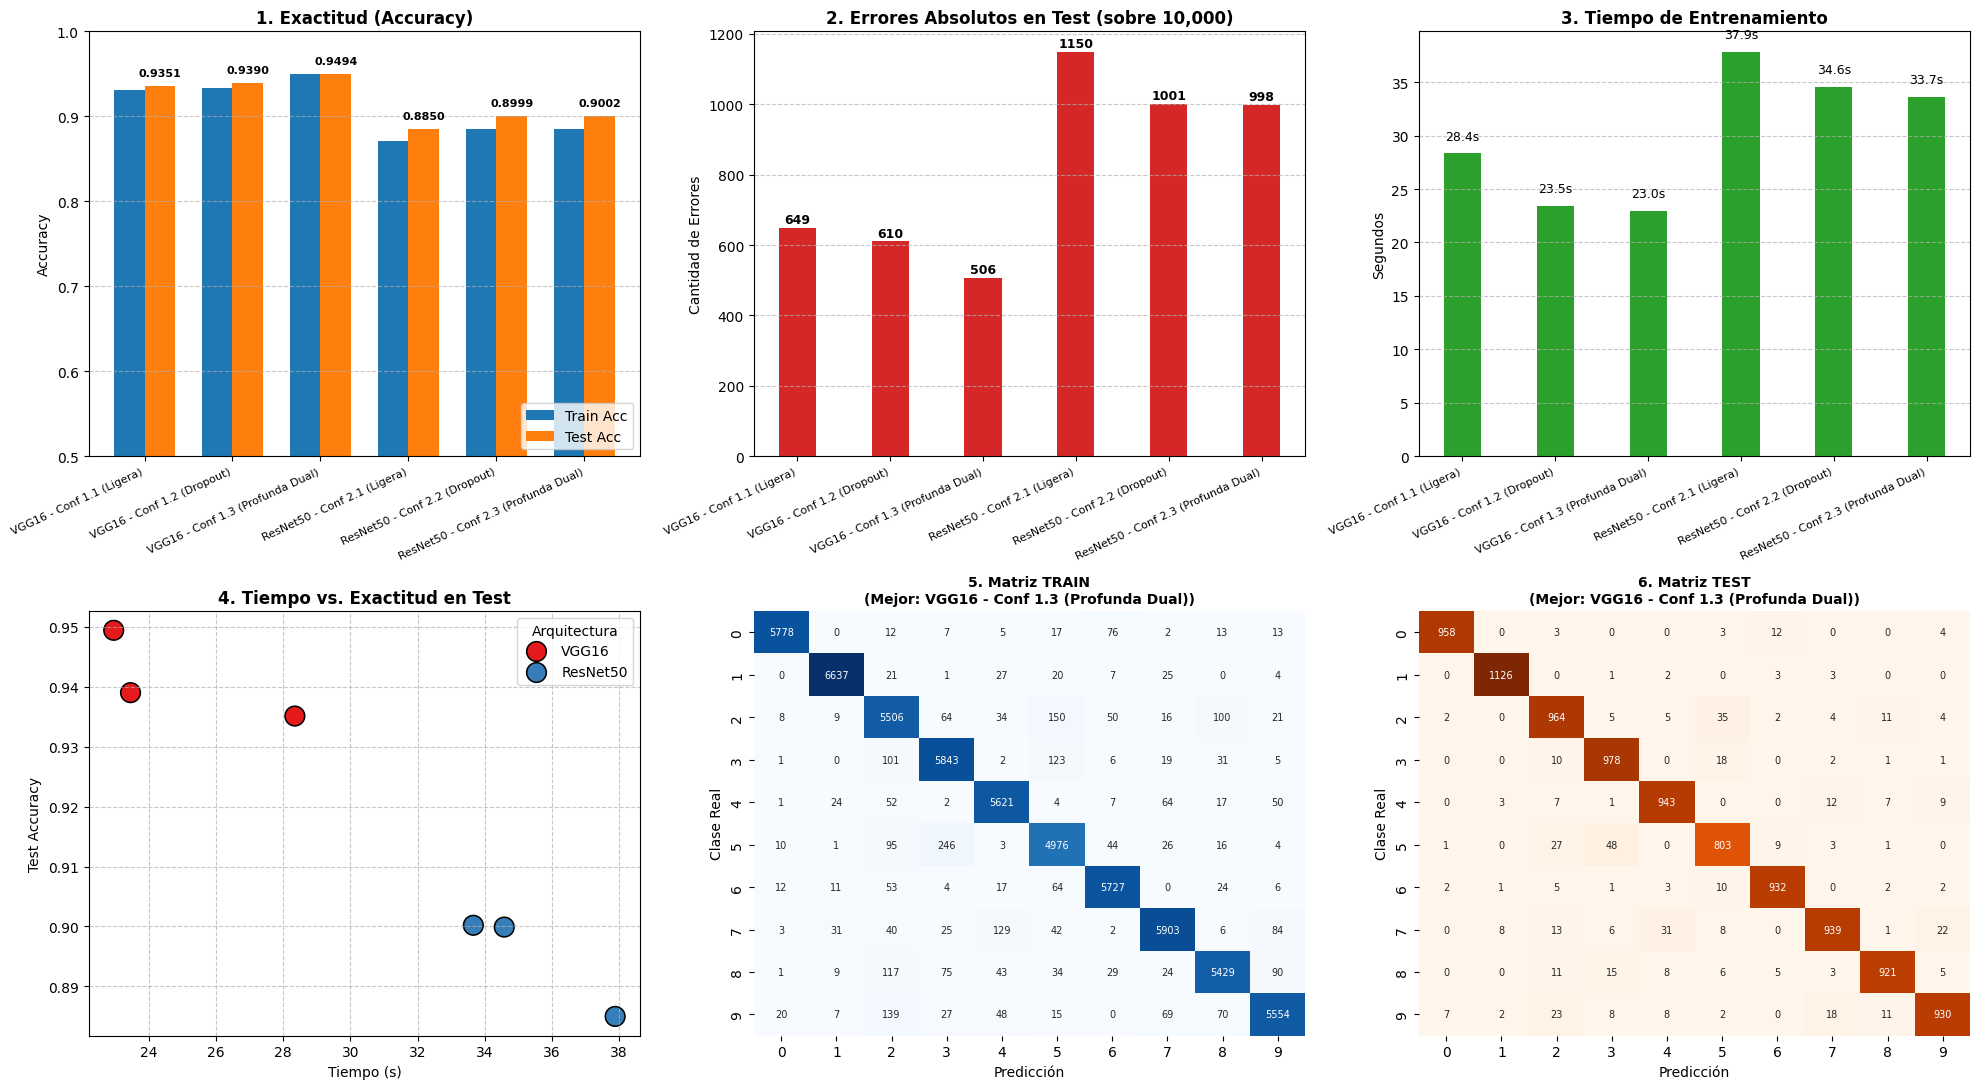


¡EL MEJOR MODELO FUE: 'VGG16 - Conf 1.3 (Profunda Dual)'!
Test Accuracy: 94.94%
Guardado correctamente en disco como: mejor_modelo_tl_mnist.keras


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import tensorflow as tf
from tensorflow.keras.applications import VGG16, ResNet50

# ==============================================================================
# 1. CARGA Y PREPROCESAMIENTO DE DATOS (TRANSFER LEARNING MNIST)
# ==============================================================================
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Reducir el dataset para agilizar la práctica si es necesario (opcional)
# Usaremos el dataset completo, pero limitaremos las épocas a 3.

# Normalización a rango [0, 1]
x_train = x_train / 255.0
x_test = x_test / 255.0

# Añadimos dimensión de canal (28, 28) -> (28, 28, 1)
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

# Los modelos VGG16 y ResNet50 requieren imágenes de al menos 32x32 y 3 canales (RGB)
print("Redimensionando imágenes a 32x32 y convirtiendo a RGB...")
x_train = tf.image.resize(x_train, [32, 32]).numpy()
x_test = tf.image.resize(x_test, [32, 32]).numpy()

x_train = np.repeat(x_train, 3, axis=-1)
x_test = np.repeat(x_test, 3, axis=-1)

# Configuramos la semilla personalizada para asegurar reproducibilidad
nombre_completo = "Manuel Farfán Fernández"
SEMILLA = sum(ord(caracter) for caracter in nombre_completo)

print(f"Práctica Transfer Learning MNIST - {nombre_completo}")
print(f"Semilla generada: {SEMILLA}\n")
tf.keras.utils.set_random_seed(SEMILLA)

# ==============================================================================
# 2. DEFINICIÓN, COMPILACIÓN Y EVALUACIÓN DE LOS MODELOS TL
# ==============================================================================
def evaluar_transfer_learning(
    modelo_base_nombre="VGG16",
    config_id="Conf 1.1 (Ligera)",
    optimizador="adam",
    epochs=3,
    batch_size=128,
):
    """
    Soporta 2 Modelos Base (VGG16, ResNet50) y 3 Configuraciones de Cabeza (Head).
    """
    model = tf.keras.models.Sequential()

    # --- INSERCIÓN DEL MODELO BASE PRE-ENTRENADO ---
    if modelo_base_nombre == "VGG16":
        base_model = VGG16(include_top=False, weights='imagenet', input_shape=(32, 32, 3))
    elif modelo_base_nombre == "ResNet50":
        base_model = ResNet50(include_top=False, weights='imagenet', input_shape=(32, 32, 3))

    # Congelamos el tronco base para no re-entrenar sus parámetros
    base_model.trainable = False

    model.add(base_model)

    # Reducción espacial unificada para todas las configuraciones
    model.add(tf.keras.layers.GlobalAveragePooling2D())

    # --- CONFIGURACIONES DE LA CABEZA DE CLASIFICACIÓN ---
    if "Ligera" in config_id:
        model.add(tf.keras.layers.Dense(32, activation="relu"))

    elif "Dropout" in config_id:
        model.add(tf.keras.layers.Dense(64, activation="relu"))
        model.add(tf.keras.layers.Dropout(0.30))

    elif "Profunda Dual" in config_id:
        model.add(tf.keras.layers.Dense(64, activation="relu"))
        model.add(tf.keras.layers.Dense(32, activation="relu"))

    # Capa de salida categórica final (10 clases)
    model.add(tf.keras.layers.Dense(10, activation="softmax"))

    # Compilación multiclase
    model.compile(
        optimizer=optimizador,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    # Entrenamiento y medición de tiempo
    inicio = time.time()
    history = model.fit(
        x_train,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.1, # Usar 10% para validación interna
        verbose=0,
    )
    tiempo_entrenamiento = time.time() - inicio

    # Obtención de predicciones (clase con mayor probabilidad)
    y_pred_train = np.argmax(model.predict(x_train, verbose=0), axis=1)
    y_pred_test = np.argmax(model.predict(x_test, verbose=0), axis=1)

    # Evaluación de loss y accuracy
    train_loss, train_acc = model.evaluate(x_train, y_train, verbose=0)
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

    # Cálculo de errores
    errores_train = np.sum(y_pred_train != y_train)
    errores_test = np.sum(y_pred_test != y_test)

    # Matrices de confusión
    cm_train = confusion_matrix(y_train, y_pred_train)
    cm_test = confusion_matrix(y_test, y_pred_test)

    nombre_exp = f"{modelo_base_nombre} - {config_id}"

    return {
        "Modelo_Obj": model,
        "Configuracion": nombre_exp,
        "Arquitectura": modelo_base_nombre,
        "Train Acc": round(train_acc, 4),
        "Test Acc": round(test_acc, 4),
        "Train Loss": round(train_loss, 4),
        "Test Loss": round(test_loss, 4),
        "Errores Train": f"{errores_train} / {len(y_train)}",
        "Errores Test": f"{errores_test} / {len(y_test)}",
        "Tiempo (s)": round(tiempo_entrenamiento, 2),
        "CM Train": cm_train,
        "CM Test": cm_test,
    }


# ==============================================================================
# 3. FUNCIÓN PARA GRAFICAR RESULTADOS COMPARATIVOS
# ==============================================================================
def graficar_comparativa_tl_mnist(df, lista_resultados_raw):
    fig, axes = plt.subplots(2, 3, figsize=(20, 11))

    x = np.arange(len(df["Configuracion"]))
    width = 0.35

    # Panel 1 (0,0): Accuracy (Train vs Test)
    axes[0, 0].bar(
        x - width / 2, df["Train Acc"], width, label="Train Acc", color="#1f77b4"
    )
    axes[0, 0].bar(
        x + width / 2, df["Test Acc"], width, label="Test Acc", color="#ff7f0e"
    )
    axes[0, 0].set_ylabel("Accuracy")
    axes[0, 0].set_title("1. Exactitud (Accuracy)", fontweight="bold")
    axes[0, 0].set_xticks(x)
    axes[0, 0].set_xticklabels(df["Configuracion"], rotation=25, ha="right", fontsize=8)
    axes[0, 0].set_ylim(0.50, 1.0) # Ajustado para TL
    axes[0, 0].legend(loc="lower right")
    axes[0, 0].grid(axis="y", linestyle="--", alpha=0.7)

    for i, val in enumerate(df["Test Acc"]):
        axes[0, 0].text(
            x[i] + width / 2, val + 0.01, f"{val:.4f}",
            ha="center", va="bottom", fontsize=8, fontweight="bold",
        )

    # Panel 2 (0,1): Errores Absolutos en Test
    errores_test_num = [int(cadena.split("/")[0].strip()) for cadena in df["Errores Test"]]
    bars_err = axes[0, 1].bar(
        df["Configuracion"], errores_test_num, color="#d62728", width=0.4
    )
    axes[0, 1].set_ylabel("Cantidad de Errores")
    axes[0, 1].set_title("2. Errores Absolutos en Test (sobre 10,000)", fontweight="bold")
    axes[0, 1].set_xticks(x)
    axes[0, 1].set_xticklabels(df["Configuracion"], rotation=25, ha="right", fontsize=8)
    axes[0, 1].grid(axis="y", linestyle="--", alpha=0.7)

    for bar in bars_err:
        yval = bar.get_height()
        axes[0, 1].text(
            bar.get_x() + bar.get_width() / 2.0, yval + 5,
            f"{int(yval)}", ha="center", va="bottom", fontsize=9, fontweight="bold",
        )

    # Panel 3 (0,2): Tiempo de Entrenamiento
    bars_time = axes[0, 2].bar(
        df["Configuracion"], df["Tiempo (s)"], color="#2ca02c", width=0.4
    )
    axes[0, 2].set_ylabel("Segundos")
    axes[0, 2].set_title("3. Tiempo de Entrenamiento", fontweight="bold")
    axes[0, 2].set_xticks(x)
    axes[0, 2].set_xticklabels(df["Configuracion"], rotation=25, ha="right", fontsize=8)
    axes[0, 2].grid(axis="y", linestyle="--", alpha=0.7)

    for bar in bars_time:
        yval = bar.get_height()
        axes[0, 2].text(
            bar.get_x() + bar.get_width() / 2.0, yval + 1,
            f"{yval:.1f}s", ha="center", va="bottom", fontsize=9,
        )

    # Selección del Mejor Modelo
    df_sorted = df.sort_values(by=["Test Acc", "Test Loss"], ascending=[False, True])
    idx_mejor = df_sorted.index[0]

    mejor_nombre = df.loc[idx_mejor, "Configuracion"]
    mejor_cm_train = lista_resultados_raw[idx_mejor]["CM Train"]
    mejor_cm_test = lista_resultados_raw[idx_mejor]["CM Test"]

    # Panel 4 (1,0): Scatter Plot Eficiencia vs Exactitud
    sns.scatterplot(
        data=df, x="Tiempo (s)", y="Test Acc", hue="Arquitectura",
        s=200, ax=axes[1, 0], palette="Set1", edgecolor="black"
    )
    axes[1, 0].set_title("4. Tiempo vs. Exactitud en Test", fontweight="bold")
    axes[1, 0].set_xlabel("Tiempo (s)")
    axes[1, 0].set_ylabel("Test Accuracy")
    axes[1, 0].grid(True, linestyle="--", alpha=0.7)

    # Panel 5 (1,1): Matriz de Confusión TRAIN (Mejor Modelo)
    labels_clases = [str(i) for i in range(10)]
    sns.heatmap(
        mejor_cm_train, annot=True, fmt="d", cmap="Blues",
        ax=axes[1, 1], cbar=False, xticklabels=labels_clases, yticklabels=labels_clases,
        annot_kws={"size": 7},
    )
    axes[1, 1].set_title(
        f"5. Matriz TRAIN\n(Mejor: {mejor_nombre})", fontweight="bold", fontsize=10
    )
    axes[1, 1].set_xlabel("Predicción")
    axes[1, 1].set_ylabel("Clase Real")

    # Panel 6 (1,2): Matriz de Confusión TEST (Mejor Modelo)
    sns.heatmap(
        mejor_cm_test, annot=True, fmt="d", cmap="Oranges",
        ax=axes[1, 2], cbar=False, xticklabels=labels_clases, yticklabels=labels_clases,
        annot_kws={"size": 7},
    )
    axes[1, 2].set_title(
        f"6. Matriz TEST\n(Mejor: {mejor_nombre})", fontweight="bold", fontsize=10
    )
    axes[1, 2].set_xlabel("Predicción")
    axes[1, 2].set_ylabel("Clase Real")

    plt.tight_layout()
    plt.show()


# ==============================================================================
# 4. EJECUCIÓN DEL EXPERIMENTO (2 Modelos Base x 3 Configuraciones = 6 Pruebas)
# ==============================================================================
print("--- Evaluando 2 Modelos Base con 3 Configuraciones cada uno ---")
# Usamos batch_size grande y pocas epochs para no saturar el tiempo de cómputo

configuraciones_exp = [
    # Base VGG16
    {"modelo_base_nombre": "VGG16", "config_id": "Conf 1.1 (Ligera)", "batch_size": 256, "epochs": 3},
    {"modelo_base_nombre": "VGG16", "config_id": "Conf 1.2 (Dropout)", "batch_size": 256, "epochs": 3},
    {"modelo_base_nombre": "VGG16", "config_id": "Conf 1.3 (Profunda Dual)", "batch_size": 256, "epochs": 3},

    # Base ResNet50
    {"modelo_base_nombre": "ResNet50", "config_id": "Conf 2.1 (Ligera)", "batch_size": 256, "epochs": 3},
    {"modelo_base_nombre": "ResNet50", "config_id": "Conf 2.2 (Dropout)", "batch_size": 256, "epochs": 3},
    {"modelo_base_nombre": "ResNet50", "config_id": "Conf 2.3 (Profunda Dual)", "batch_size": 256, "epochs": 3},
]

resultados_exp = []
modelos_objetos = []

for cfg in configuraciones_exp:
    res = evaluar_transfer_learning(**cfg)
    modelos_objetos.append(res.pop("Modelo_Obj"))
    resultados_exp.append(res)

df_comparativa = pd.DataFrame(resultados_exp)[
    [
        "Configuracion",
        "Arquitectura",
        "Train Acc",
        "Test Acc",
        "Train Loss",
        "Test Loss",
        "Errores Train",
        "Errores Test",
        "Tiempo (s)",
    ]
]

# Mostrar Tabla Completa
print("\n" + "=" * 95)
print("TABLA COMPARATIVA DE RESULTADOS TRANSFER LEARNING (MNIST 32x32 RGB)")
print("=" * 95)
print(df_comparativa.to_string(index=False))

# Generar Gráficos
graficar_comparativa_tl_mnist(df_comparativa, resultados_exp)


# ==============================================================================
# 5. SELECCIÓN Y GUARDADO DEL MEJOR MODELO EN DISCO
# ==============================================================================
idx_mejor = df_comparativa.sort_values(
    by=["Test Acc", "Test Loss"], ascending=[False, True]
).index[0]

mejor_modelo = modelos_objetos[idx_mejor]
nombre_mejor = df_comparativa.loc[idx_mejor, "Configuracion"]
acc_mejor = df_comparativa.loc[idx_mejor, "Test Acc"]

ruta_guardado = "mejor_modelo_tl_mnist.keras"
mejor_modelo.save(ruta_guardado)

print("\n" + "=" * 95)
print(f"¡EL MEJOR MODELO FUE: '{nombre_mejor}'!")
print(f"Test Accuracy: {acc_mejor * 100:.2f}%")
print(f"Guardado correctamente en disco como: {ruta_guardado}")
print("=" * 95)

## 4. Configuración del Modelo Ganador

El experimento de aprendizaje por transferencia ha determinado que **VGG16 - Conf 1.3 (Profunda Dual)** es la arquitectura óptima para la clasificación multiclase de MNIST, alcanzando una exactitud del **94.94% en Test** con **506 errores** sobre 10.000 imágenes, destacando además por su eficiencia en el tiempo de ejecución.

---

### 4.1. Resumen de Métricas del Modelo Ganador

| Métrica | Valor Obtenido |
| :--- | :--- |
| **Configuración Seleccionada** | VGG16 - Conf 1.3 (Profunda Dual) |
| **Test Accuracy** | **94.94%** (`0.9494`) |
| **Train Accuracy** | **94.96%** (`0.9496`) |
| **Test / Train Loss** | `0.1597` / `0.1672` |
| **Errores en Test / Train** | **506 / 10.000** \| **3.026 / 60.000** |
| **Tiempo de Entrenamiento** | $22.96\text{ s}$ ($3\text{ épocas}$) |
| **Fichero Guardado** | `mejor_modelo_tl_mnist.keras` |

---

### 4.2. Especificación Técnica Breve

- **Entrada:** Tensores de $32 \times 32 \times 3$ (RGB) procesados con escalado estándar ($/ 255.0$).
- **Base Pre-entrenada:** `VGG16` (Pesos de ImageNet, `include_top=False`, capas congeladas).
- **Capa de Enlace:** `GlobalAveragePooling2D` (Reducción espacial de mapas de características a vector 1D).
- **Cabeza de Clasificación (Añadida):** `Dense(64, ReLU)` $\rightarrow$ `Dense(32, ReLU)` $\rightarrow$ `Dense(10, Softmax)`.
- **Hiperparámetros:** Optimizador `Adam`, Pérdida `sparse_categorical_crossentropy`, *Batch Size* $256$, $3$ épocas.

---

### 4.3. Justificación Técnica

1. **Extracción y Convergencia:** El modelo VGG16 demuestra una adaptabilidad superior frente a ResNet50 en resoluciones bajas ($32 \times 32$), ya que sus bloques convolucionales logran extraer características relevantes de los trazos simples de los dígitos sin verse penalizados por la complejidad residual de redes más profundas.
2. **Estructura del Embudo Dual:** La configuración Profunda Dual (`64 -> 32`) permite una destilación no lineal de los indicios visuales (los 512 canales de salida de VGG16). Las dos capas densas actúan como un comité que combina características locales en "prototipos lógicos", reduciendo el ruido de la clasificación en un solo paso y superando el rendimiento de las versiones Ligeras y con Dropout.
3. **Eficiencia Computacional:** A pesar de tener una cabeza de clasificación más profunda, al estar las capas base congeladas y usar la operación matemática de `GlobalAveragePooling2D` para evitar el aplanado de datos espaciales masivos, es la configuración más rápida del experimento en converger ($22.96$ s).